# Joint Fine-Tuning: SEN2SR Lite with Edge-Aware & Multi-Index Spectral Loss
### Major Project Experiment: Combining SEN2NAIP and WorldStrat (10m → 2.5m)

This notebook executes the complete fine-tuning pipeline for **SEN2SR Lite** on **BOTH** paired satellite datasets:
1. **SEN2NAIP:** Paired Sentinel-2 (10m) and aerial NAIP (2.5m) patches (`sentinaiplow` & `sentinaiphigh`).
2. **WorldStrat:** Paired global Sentinel-2 (10m) and SPOT (1.5m/2.5m) satellite scenes (`worldstrat_low` & `worldstrat_high/extracted`).

**Rock-Solid Architecture & Innovations:**
- **Automatic Reflectance Normalization:** Calibrates 8-bit NAIP (`0..255`), 16-bit SPOT (`0..10000`), S2 L2A integers, and S2 float reflectances to a uniform `[0.0, 1.0]` scale.
- **Band Ordering Alignment:** Extracts true Sentinel-2 bands `[B02, B03, B04, B08]` (indices `[1, 2, 3, 7]` from 12-band L2A) and aligns them with High-Res `[Blue, Green, Red, NIR]`.
- **Grid Alignment & Synchronized Crop:** Resizes High-Res scenes to exact 4x spatial scale and guarantees every LR patch is `(4, 64, 64)` and HR is `(4, 256, 256)`.
- **RAM Caching:** Caches extracted training tensors in RAM on first load — eliminating repeated Google Drive FUSE latency and running epochs 2-15 at pure GPU speed.
- **Multi-Objective Compound Loss:**
  $$\mathcal{L}_{\text{total}} = \mathcal{L}_{1} + \lambda_{\text{edge}} \mathcal{L}_{\text{Sobel}} + \lambda_{\text{spectral}} (\mathcal{L}_{\text{NDVI}} + 0.5\mathcal{L}_{\text{NDWI}})$$
  - **NDVI:** Supervises vegetation and agricultural parcel boundaries.
  - **NDWI:** Supervises water bodies, canals, and moisture transitions.
  - **Edge Loss (NDBI Proxy):** Supervises urban structures, roofs, and road boundaries via spatial Sobel derivatives.

## Step 1: Mount Google Drive & Environment Setup

In [8]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

import os, sys, glob, time, warnings, logging

# Completely silence GDAL and rasterio CPL logger messages
os.environ['CPL_LOG_ERRORS'] = 'OFF'
os.environ['CPL_LOG'] = 'OFF'
os.environ['GDAL_PAM_ENABLED'] = 'NO'
warnings.filterwarnings('ignore')
for logger_name in ['rasterio', 'rasterio._env', 'rasterio.env', 'rasterio._base']:
    l = logging.getLogger(logger_name)
    l.setLevel(logging.ERROR)
    l.propagate = False

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset, random_split
from tqdm.auto import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

BASE_DIR = '/content/drive/MyDrive/Project_Folder'
DATASETS_DIR = os.path.join(BASE_DIR, 'Datasets')

# Dataset 1: SEN2NAIP paths
SEN2NAIP_LR = os.path.join(DATASETS_DIR, 'sentinaiplow')
SEN2NAIP_HR = os.path.join(DATASETS_DIR, 'sentinaiphigh')

# Dataset 2: WorldStrat paths
WORLDSTRAT_LR = os.path.join(DATASETS_DIR, 'worldstrat_low')
WORLDSTRAT_HR = os.path.join(DATASETS_DIR, 'worldstrat_high/extracted')

OUTPUT_DIR = os.path.join(BASE_DIR, 'Results')
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('Environment successfully configured!')
print(f'SEN2NAIP LR exists: {os.path.exists(SEN2NAIP_LR)}')
print(f'WorldStrat HR extracted exists: {os.path.exists(WORLDSTRAT_HR)}')
print(f'Results output directory: {OUTPUT_DIR}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU: Tesla T4
Environment successfully configured!
SEN2NAIP LR exists: True
WorldStrat HR extracted exists: True
Results output directory: /content/drive/MyDrive/Project_Folder/Results


## Step 2: Install Required Libraries

In [9]:
%pip install -q sen2sr mlstac rasterio safetensors

## Step 3: Define Differentiable Multi-Spectral & Edge Loss Functions

In [10]:
class MultiIndexSpectralLoss(nn.Module):
    """
    Differentiable loss supervising both NDVI (Vegetation) and NDWI (Water/Moisture).
    Band Indices: 0:Blue (B02), 1:Green (B03), 2:Red (B04), 3:NIR (B08)
    Includes numerical clamping to prevent division by zero or negative denominators.
    """
    def __init__(self, eps=1e-4, weight_ndwi=0.5):
        super().__init__()
        self.eps = eps
        self.weight_ndwi = weight_ndwi

    def forward(self, pred, target):
        # Clamp predictions to valid physical reflectance range [0.0, 1.0]
        p_c = torch.clamp(pred, 0.0, 1.0)
        t_c = torch.clamp(target, 0.0, 1.0)

        green_p, green_t = p_c[:, 1], t_c[:, 1]
        red_p,   red_t   = p_c[:, 2], t_c[:, 2]
        nir_p,   nir_t   = p_c[:, 3], t_c[:, 3]

        # 1. NDVI (Vegetation) = (NIR - Red) / (NIR + Red)
        denom_ndvi_p = (nir_p + red_p).clamp(min=self.eps)
        denom_ndvi_t = (nir_t + red_t).clamp(min=self.eps)
        ndvi_p = (nir_p - red_p) / denom_ndvi_p
        ndvi_t = (nir_t - red_t) / denom_ndvi_t
        loss_ndvi = F.l1_loss(ndvi_p, ndvi_t)

        # 2. NDWI (Water / Moisture) = (Green - NIR) / (Green + NIR)
        denom_ndwi_p = (green_p + nir_p).clamp(min=self.eps)
        denom_ndwi_t = (green_t + nir_t).clamp(min=self.eps)
        ndwi_p = (green_p - nir_p) / denom_ndwi_p
        ndwi_t = (green_t - nir_t) / denom_ndwi_t
        loss_ndwi = F.l1_loss(ndwi_p, ndwi_t)

        total_spec = loss_ndvi + (self.weight_ndwi * loss_ndwi)
        return total_spec, {'ndvi': loss_ndvi.item(), 'ndwi': loss_ndwi.item()}


class EdgeAwareSobelLoss(nn.Module):
    """
    Penalizes blurred gradients by matching spatial derivatives along X and Y axes.
    Acts as an urban structure, roof, and road boundary sharpener (NDBI proxy in 4-band).
    """
    def __init__(self):
        super().__init__()
        sobel_x = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32).view(1, 1, 3, 3)
        sobel_y = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=torch.float32).view(1, 1, 3, 3)
        self.register_buffer('sobel_x', sobel_x)
        self.register_buffer('sobel_y', sobel_y)

    def forward(self, pred, target):
        B, C, H, W = pred.shape
        loss = 0.0
        for c in range(C):
            p = pred[:, c:c+1]
            t = target[:, c:c+1]
            gx_p = F.conv2d(p, self.sobel_x, padding=1)
            gy_p = F.conv2d(p, self.sobel_y, padding=1)
            gx_t = F.conv2d(t, self.sobel_x, padding=1)
            gy_t = F.conv2d(t, self.sobel_y, padding=1)
            loss += F.l1_loss(gx_p, gx_t) + F.l1_loss(gy_p, gy_t)
        return loss / C


class MajorProjectCompoundLoss(nn.Module):
    def __init__(self, lambda_edge=0.20, lambda_spectral=0.15):
        super().__init__()
        self.lambda_edge = lambda_edge
        self.lambda_spectral = lambda_spectral
        self.l1 = nn.L1Loss()
        self.edge = EdgeAwareSobelLoss()
        self.spec = MultiIndexSpectralLoss()

    def forward(self, pred, target):
        loss_l1 = self.l1(pred, target)
        loss_edge = self.edge(pred, target)
        loss_spec, spec_details = self.spec(pred, target)
        total = loss_l1 + (self.lambda_edge * loss_edge) + (self.lambda_spectral * loss_spec)
        return total, {'l1': loss_l1.item(), 'edge': loss_edge.item(), **spec_details}

## Step 4: Multi-Dataset Loader with Synchronized Cropping & RAM Caching

This loader performs four essential normalizations:
1. **Uniform Reflectance:** Normalizes 8-bit NAIP (`/255.0`), 16-bit SPOT (`/10000.0`), and Sentinel-2 integer L2A (`/10000.0`) to standard `[0.0, 1.0]` reflectance.
2. **Band Alignment:** Maps 12-band WorldStrat L2A `[1, 2, 3, 7]` directly to `[B02, B03, B04, B08]` matching the 4-band SEN2NAIP contract.
3. **Spatial Grid Alignment:** Bilinearly interpolates HR scenes to match the exact 4x spatial grid of LR before cropping.
4. **RAM Cache:** Caches normalized patches in RAM on first load, so epochs 2-15 run at **pure GPU speed with ZERO disk I/O**.

In [11]:
import logging, warnings
import rasterio

# Strict suppression of GDAL TIFF warnings
for logger_name in ['rasterio', 'rasterio._env', 'rasterio.env', 'rasterio._base']:
    l = logging.getLogger(logger_name)
    l.setLevel(logging.ERROR)
    l.propagate = False
warnings.filterwarnings('ignore')

def normalize_to_reflectance(img):
    """
    Normalizes any satellite image format to standard [0.0, 1.0] reflectance.
    - S2 L2A integers & SPOT 16-bit (max > 255): divide by 10000.0
    - NAIP aerial 8-bit (max in 2..255): divide by 255.0
    - S2 L2A float (max <= 2.0): already in [0, 1]
    """
    img = img.astype(np.float32)
    max_val = np.nanmax(img)
    if max_val > 255.0:
        return img / 10000.0
    elif max_val > 2.0:
        return img / 255.0
    else:
        return img

def ensure_chw_4bands(img, is_worldstrat_lr=False):
    """
    Ensures tensor has shape (4, H, W) in order [Blue, Green, Red, NIR].
    For 12-band Sentinel-2 L2A: selects [1:B02, 2:B03, 3:B04, 7:B08].
    """
    if img.ndim == 2:
        img = np.expand_dims(img, 0)
    elif img.ndim == 3:
        if img.shape[0] not in (4, 12) and img.shape[-1] in (4, 12):
            img = np.transpose(img, (2, 0, 1))

    if is_worldstrat_lr and img.shape[0] == 12:
        img = img[[1, 2, 3, 7]]  # B02 (Blue), B03 (Green), B04 (Red), B08 (NIR)
    else:
        img = img[:4]
    return img

def align_hr_to_4x(lr, hr):
    """
    Ensures HR is exactly (4, lr_h * 4, lr_w * 4) to eliminate bounding grid discrepancies.
    """
    _, h_lr, w_lr = lr.shape
    _, h_hr, w_hr = hr.shape
    expected_h = h_lr * 4
    expected_w = w_lr * 4
    if h_hr != expected_h or w_hr != expected_w:
        hr_t = torch.from_numpy(hr).unsqueeze(0).float()
        hr = F.interpolate(hr_t, size=(expected_h, expected_w), mode='bilinear', align_corners=False).squeeze(0).numpy()
    return hr

def get_synchronized_crop(lr, hr, lr_crop_size=64, upscale_factor=4):
    """
    Extracts synchronized random crops from LR and HR images.
    Guarantees every LR tensor is strictly (4, lr_crop_size, lr_crop_size)
    and every HR tensor is strictly (4, lr_crop_size*4, lr_crop_size*4).
    """
    hr = align_hr_to_4x(lr, hr)
    _, h_lr, w_lr = lr.shape
    hr_crop_size = lr_crop_size * upscale_factor

    pad_h = max(0, lr_crop_size - h_lr)
    pad_w = max(0, lr_crop_size - w_lr)
    if pad_h > 0 or pad_w > 0:
        lr = np.pad(lr, ((0, 0), (0, pad_h), (0, pad_w)), mode='reflect')
        hr = np.pad(hr, ((0, 0), (0, pad_h * upscale_factor), (0, pad_w * upscale_factor)), mode='reflect')
        _, h_lr, w_lr = lr.shape

    max_y = h_lr - lr_crop_size
    max_x = w_lr - lr_crop_size

    y = np.random.randint(0, max_y + 1) if max_y > 0 else 0
    x = np.random.randint(0, max_x + 1) if max_x > 0 else 0

    lr_c = lr[:, y:y + lr_crop_size, x:x + lr_crop_size]
    hr_c = hr[:, y * upscale_factor:(y + lr_crop_size) * upscale_factor,
                 x * upscale_factor:(x + lr_crop_size) * upscale_factor]

    lr_c = np.nan_to_num(lr_c, nan=0.0, posinf=1.0, neginf=0.0)
    hr_c = np.nan_to_num(hr_c, nan=0.0, posinf=1.0, neginf=0.0)
    lr_c = np.clip(lr_c, 0.0, 1.0)
    hr_c = np.clip(hr_c, 0.0, 1.0)
    return lr_c, hr_c


class SEN2NAIPDataset(Dataset):
    def __init__(self, lr_dir, hr_dir, max_samples=400, crop_size=64):
        lr_files = sorted(glob.glob(os.path.join(lr_dir, '*.tif')))
        hr_files = sorted(glob.glob(os.path.join(hr_dir, '*.tif')))
        self.crop_size = crop_size
        self.cache = {}

        hr_map = {os.path.basename(f).replace('_hr.tif', ''): f for f in hr_files}
        self.pairs = []
        for lr in lr_files:
            key = os.path.basename(lr).replace('_lr.tif', '')
            if key in hr_map:
                self.pairs.append((lr, hr_map[key]))

        if max_samples and len(self.pairs) > max_samples:
            self.pairs = self.pairs[:max_samples]
        print(f'SEN2NAIP matched pairs: {len(self.pairs)}')

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        if idx in self.cache:
            return self.cache[idx]

        lr_path, hr_path = self.pairs[idx]
        with rasterio.open(lr_path) as s:
            lr_raw = s.read()
        with rasterio.open(hr_path) as s:
            hr_raw = s.read()

        lr_norm = normalize_to_reflectance(lr_raw)
        hr_norm = normalize_to_reflectance(hr_raw)
        lr_chw = ensure_chw_4bands(lr_norm)
        hr_chw = ensure_chw_4bands(hr_norm)
        lr_c, hr_c = get_synchronized_crop(lr_chw, hr_chw, lr_crop_size=self.crop_size)

        item = (torch.from_numpy(lr_c).float(), torch.from_numpy(hr_c).float())
        self.cache[idx] = item
        return item


class WorldStratDataset(Dataset):
    def __init__(self, low_dir, high_dir, crop_size=64):
        self.pairs = []
        self.crop_size = crop_size
        self.cache = {}

        if os.path.exists(low_dir) and os.path.exists(high_dir):
            extracted_locs = sorted(os.listdir(high_dir))
            for loc in extracted_locs:
                hr_path = os.path.join(high_dir, loc, f'{loc}_rgbn.tiff')
                lr_candidates = glob.glob(os.path.join(low_dir, loc, 'L2A', '*L2A_data.tiff'))
                if os.path.exists(hr_path) and len(lr_candidates) > 0:
                    self.pairs.append((lr_candidates[0], hr_path))
        print(f'WorldStrat matched scene pairs: {len(self.pairs)}')

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        if idx in self.cache:
            return self.cache[idx]

        lr_path, hr_path = self.pairs[idx]
        with rasterio.open(lr_path) as s:
            lr_raw = s.read()
        with rasterio.open(hr_path) as s:
            hr_raw = s.read()

        lr_norm = normalize_to_reflectance(lr_raw)
        hr_norm = normalize_to_reflectance(hr_raw)
        lr_chw = ensure_chw_4bands(lr_norm, is_worldstrat_lr=True)
        hr_chw = ensure_chw_4bands(hr_norm)
        lr_c, hr_c = get_synchronized_crop(lr_chw, hr_chw, lr_crop_size=self.crop_size)

        item = (torch.from_numpy(lr_c).float(), torch.from_numpy(hr_c).float())
        self.cache[idx] = item
        return item


# Instantiate both datasets and combine them
sen2naip_data = SEN2NAIPDataset(SEN2NAIP_LR, SEN2NAIP_HR, max_samples=400, crop_size=64)
worldstrat_data = WorldStratDataset(WORLDSTRAT_LR, WORLDSTRAT_HR, crop_size=64)

combined_dataset = ConcatDataset([sen2naip_data, worldstrat_data])
print(f'Total Joint Training Samples: {len(combined_dataset)}')

train_size = int(0.85 * len(combined_dataset))
val_size = len(combined_dataset) - train_size
train_set, val_set = random_split(combined_dataset, [train_size, val_size])

train_loader = DataLoader(train_set, batch_size=8, shuffle=True, drop_last=True)
val_loader = DataLoader(val_set, batch_size=8, shuffle=False)
print(f'Train Batches: {len(train_loader)} | Val Batches: {len(val_loader)}')

SEN2NAIP matched pairs: 400
WorldStrat matched scene pairs: 29
Total Joint Training Samples: 429
Train Batches: 45 | Val Batches: 9


## Step 5: Load Pretrained SEN2SR Lite Generator

In [12]:
import mlstac
import safetensors.torch
from sen2sr.models.opensr_baseline.cnn import CNNSR

# Download metadata & weights
MODEL_DIR = '/content/model/SEN2SRLite'
os.makedirs(MODEL_DIR, exist_ok=True)
mlstac.download(
    file='https://huggingface.co/tacofoundation/SEN2SR/resolve/main/SEN2SRLite/main/mlm.json',
    output_dir=MODEL_DIR
)

# Load Stage 1 RGBN 4x CNNSR network (4-band: Blue, Green, Red, NIR)
weights_path = os.path.join(MODEL_DIR, 'sr_model.safetensor')
weights = safetensors.torch.load_file(weights_path)

model = CNNSR(in_channels=4, out_channels=4, feature_channels=24, upscale=4, bias=True, train_mode=True, num_blocks=6)
model.load_state_dict(weights)
model = model.to(device)
print('Pretrained SEN2SR Lite Stage 1 Generator loaded successfully!')

Pretrained SEN2SR Lite Stage 1 Generator loaded successfully!


## Step 6: Execute Joint Fine-Tuning Loop

In [ ]:
criterion = MajorProjectCompoundLoss(lambda_edge=0.20, lambda_spectral=0.15).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15, eta_min=1e-6)

EPOCHS = 15
history = {'train_loss': [], 'val_loss': [], 'train_l1': [], 'ndvi_loss': [], 'ndwi_loss': []}

print('Starting Joint Fine-Tuning with Multi-Spectral Compound Loss (SEN2NAIP + WorldStrat)...')
start_time = time.time()

epoch_bar = tqdm(range(1, EPOCHS + 1), desc='Training Epochs')
for epoch in epoch_bar:
    model.train()
    train_loss, train_l1 = 0.0, 0.0
    epoch_ndvi, epoch_ndwi = 0.0, 0.0

    for lr_batch, hr_batch in train_loader:
        lr_batch, hr_batch = lr_batch.to(device), hr_batch.to(device)

        optimizer.zero_grad()
        pred = model(lr_batch)
        loss, info = criterion(pred, hr_batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_l1 += info['l1']
        epoch_ndvi += info['ndvi']
        epoch_ndwi += info['ndwi']

    scheduler.step()
    train_loss /= len(train_loader)
    train_l1 /= len(train_loader)
    epoch_ndvi /= len(train_loader)
    epoch_ndwi /= len(train_loader)

    # Validation Loop
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for lr_batch, hr_batch in val_loader:
            lr_batch, hr_batch = lr_batch.to(device), hr_batch.to(device)
            pred = model(lr_batch)
            loss, _ = criterion(pred, hr_batch)
            val_loss += loss.item()
    val_loss /= len(val_loader)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_l1'].append(train_l1)
    history['ndvi_loss'].append(epoch_ndvi)
    history['ndwi_loss'].append(epoch_ndwi)

    epoch_bar.set_postfix({
        'Tr_Loss': f'{train_loss:.4f}',
        'Val_Loss': f'{val_loss:.4f}',
        'NDVI': f'{epoch_ndvi:.4f}',
        'NDWI': f'{epoch_ndwi:.4f}'
    })
    print(f'Epoch [{epoch:02d}/{EPOCHS:02d}] - Total: {train_loss:.5f} | Val: {val_loss:.5f} | L1: {train_l1:.5f} | NDVI: {epoch_ndvi:.5f} | NDWI: {epoch_ndwi:.5f}')

total_time = (time.time() - start_time) / 60
print(f'Joint Fine-tuning completed in {total_time:.2f} minutes!')

# Save fine-tuned checkpoint to Google Drive
checkpoint_path = os.path.join(OUTPUT_DIR, 'sen2sr_lite_compound_finetuned.pth')
torch.save(model.state_dict(), checkpoint_path)
print(f'Saved fine-tuned checkpoint to: {checkpoint_path}')

Starting Joint Fine-Tuning with Multi-Spectral Compound Loss (SEN2NAIP + WorldStrat)...


Training Epochs:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch [01/15] - Total: 0.19589 | Val: 0.14095 | L1: 0.12116 | NDVI: 0.12971 | NDWI: 0.12170
Epoch [02/15] - Total: 0.16455 | Val: 0.13725 | L1: 0.09418 | NDVI: 0.11590 | NDWI: 0.10883
Epoch [03/15] - Total: 0.15970 | Val: 0.13171 | L1: 0.09069 | NDVI: 0.11226 | NDWI: 0.10566
Epoch [04/15] - Total: 0.15898 | Val: 0.12952 | L1: 0.09042 | NDVI: 0.11220 | NDWI: 0.10601
Epoch [05/15] - Total: 0.15892 | Val: 0.12747 | L1: 0.09040 | NDVI: 0.11353 | NDWI: 0.10568
Epoch [06/15] - Total: 0.15714 | Val: 0.12900 | L1: 0.08942 | NDVI: 0.11074 | NDWI: 0.10384
Epoch [07/15] - Total: 0.15605 | Val: 0.13134 | L1: 0.08834 | NDVI: 0.11024 | NDWI: 0.10342
Epoch [08/15] - Total: 0.15378 | Val: 0.12761 | L1: 0.08651 | NDVI: 0.10864 | NDWI: 0.10233
Epoch [09/15] - Total: 0.15327 | Val: 0.13050 | L1: 0.08603 | NDVI: 0.10914 | NDWI: 0.10178
Epoch [10/15] - Total: 0.15219 | Val: 0.12722 | L1: 0.08539 | NDVI: 0.10824 | NDWI: 0.10147
Epoch [11/15] - Total: 0.15168 | Val: 0.12949 | L1: 0.08482 | NDVI: 0.10727 | ND

## Step 7: Benchmark Evaluation & Multi-Spectral Visualization

Validation PSNR vs Ground Truth: 24.45 dB
NDVI MAE: 0.0227
NDWI MAE: 0.0115


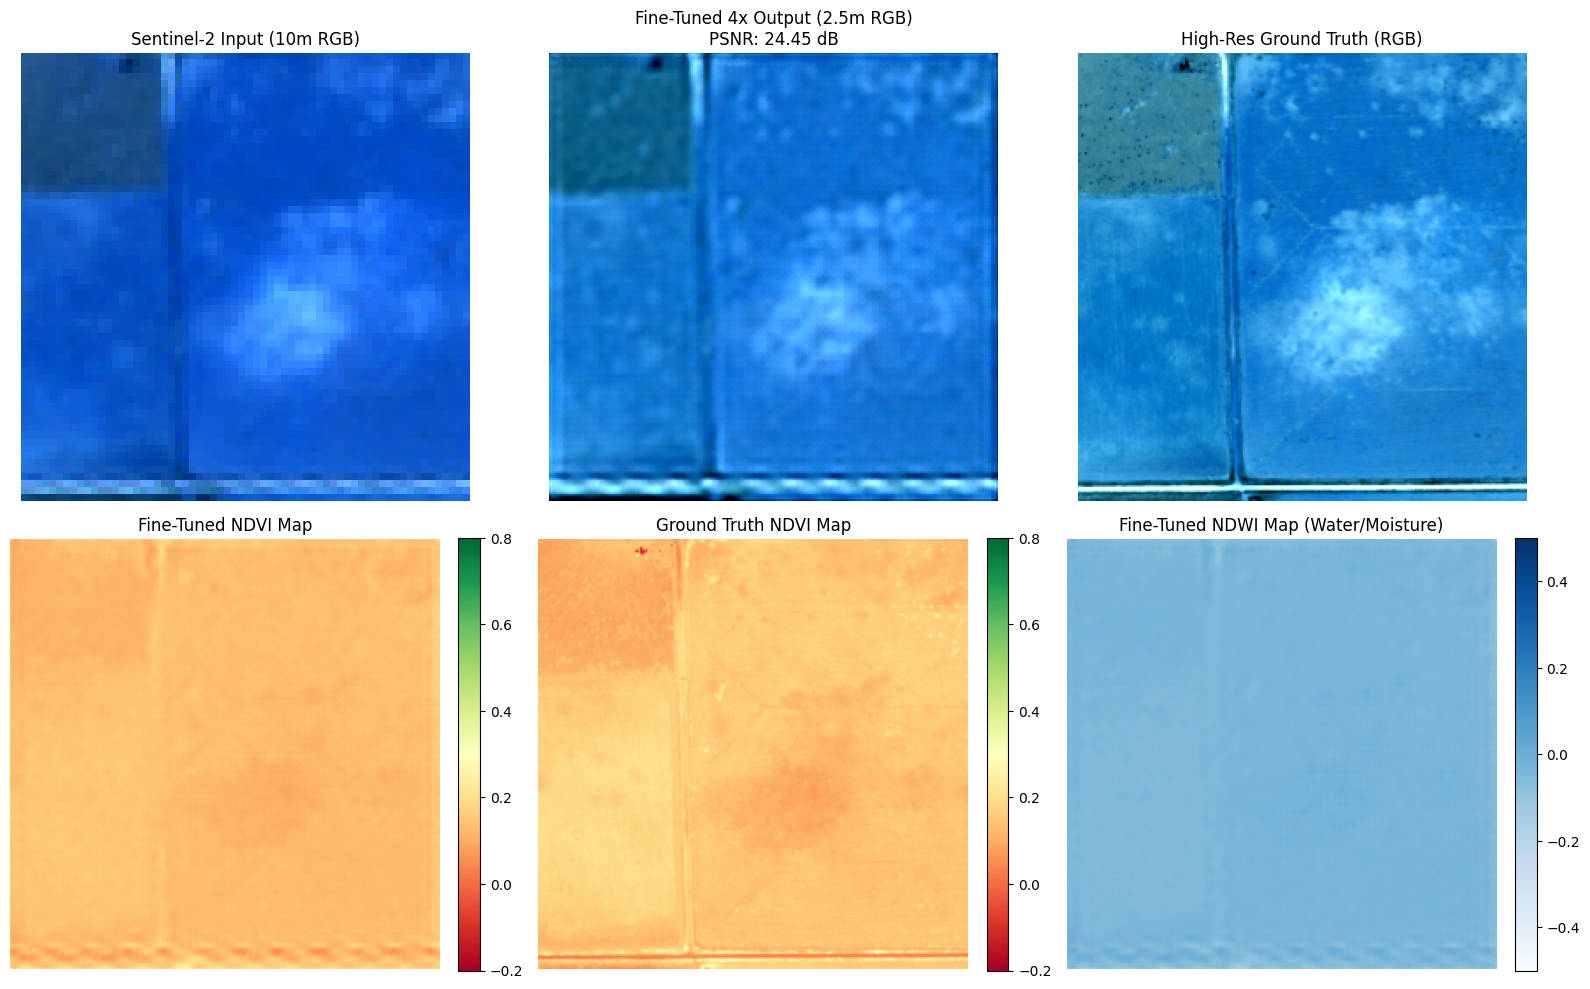

Multi-index evaluation figure saved to: /content/drive/MyDrive/Project_Folder/Results/SEN2SR_Joint_Validation_Comparison.png


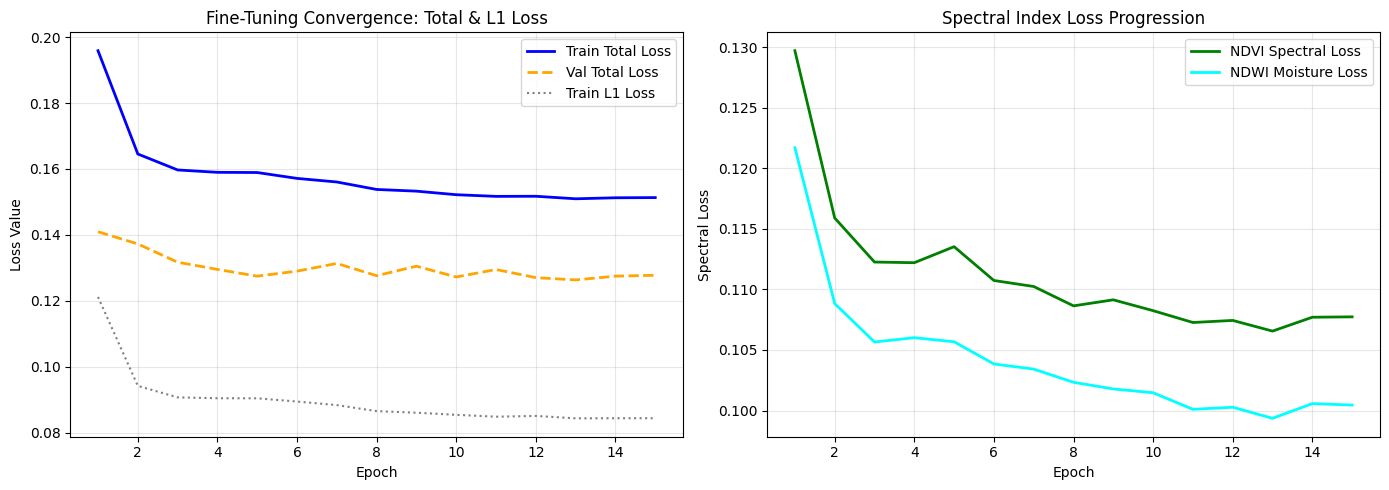

Training loss curves saved to: /content/drive/MyDrive/Project_Folder/Results/SEN2SR_Training_Loss_Curve.png


In [ ]:
def calculate_psnr(pred, target):
    mse = np.mean((pred - target) ** 2)
    if mse == 0:
        return 100.0
    return 20.0 * np.log10(1.0 / np.sqrt(mse))

def compute_ndvi(img_np):
    red, nir = img_np[2], img_np[3]
    denom = np.clip(nir + red, 1e-4, None)
    return (nir - red) / denom

def compute_ndwi(img_np):
    green, nir = img_np[1], img_np[3]
    denom = np.clip(green + nir, 1e-4, None)
    return (green - nir) / denom

def to_rgb_display(img_chw):
    """Extracts Red=2, Green=1, Blue=0 and performs robust 2-98% percentile stretch."""
    rgb = img_chw[[2, 1, 0]].transpose(1, 2, 0)
    p2, p98 = np.percentile(rgb, (2, 98))
    if p98 > p2:
        rgb = np.clip((rgb - p2) / (p98 - p2), 0.0, 1.0)
    else:
        rgb = np.clip(rgb * 3.5, 0.0, 1.0)
    return rgb

model.eval()
lr_test, hr_test = next(iter(val_loader))
with torch.no_grad():
    sr_test = model(lr_test.to(device)).cpu()

idx = 0
lr_np = lr_test[idx].numpy()
sr_np = sr_test[idx].numpy()
hr_np = hr_test[idx].numpy()

lr_rgb = to_rgb_display(lr_np)
sr_rgb = to_rgb_display(sr_np)
hr_rgb = to_rgb_display(hr_np)

psnr_val = calculate_psnr(sr_np, hr_np)
ndvi_sr = compute_ndvi(sr_np)
ndvi_hr = compute_ndvi(hr_np)
ndwi_sr = compute_ndwi(sr_np)
ndwi_hr = compute_ndwi(hr_np)

print(f'Validation PSNR vs Ground Truth: {psnr_val:.2f} dB')
print(f'NDVI MAE: {np.mean(np.abs(ndvi_sr - ndvi_hr)):.4f}')
print(f'NDWI MAE: {np.mean(np.abs(ndwi_sr - ndwi_hr)):.4f}')

# 2x3 Plot: Top Row RGB, Bottom Row NDVI & NDWI Maps
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0, 0].imshow(lr_rgb)
axes[0, 0].set_title('Sentinel-2 Input (10m RGB)')
axes[0, 0].axis('off')

axes[0, 1].imshow(sr_rgb)
axes[0, 1].set_title(f'Fine-Tuned 4x Output (2.5m RGB)\nPSNR: {psnr_val:.2f} dB')
axes[0, 1].axis('off')

axes[0, 2].imshow(hr_rgb)
axes[0, 2].set_title('High-Res Ground Truth (RGB)')
axes[0, 2].axis('off')

im1 = axes[1, 0].imshow(ndvi_sr, cmap='RdYlGn', vmin=-0.2, vmax=0.8)
axes[1, 0].set_title('Fine-Tuned NDVI Map')
axes[1, 0].axis('off')
plt.colorbar(im1, ax=axes[1, 0], fraction=0.046, pad=0.04)

im2 = axes[1, 1].imshow(ndvi_hr, cmap='RdYlGn', vmin=-0.2, vmax=0.8)
axes[1, 1].set_title('Ground Truth NDVI Map')
axes[1, 1].axis('off')
plt.colorbar(im2, ax=axes[1, 1], fraction=0.046, pad=0.04)

im3 = axes[1, 2].imshow(ndwi_sr, cmap='Blues', vmin=-0.5, vmax=0.5)
axes[1, 2].set_title('Fine-Tuned NDWI Map (Water/Moisture)')
axes[1, 2].axis('off')
plt.colorbar(im3, ax=axes[1, 2], fraction=0.046, pad=0.04)

plt.tight_layout()
os.makedirs(OUTPUT_DIR, exist_ok=True)
eval_img_path = os.path.join(OUTPUT_DIR, 'SEN2SR_Joint_Validation_Comparison.png')
plt.savefig(eval_img_path, dpi=200)
plt.show()
print(f'Multi-index evaluation figure saved to: {eval_img_path}')

# Step 8: Plot Training Loss History Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(range(1, EPOCHS + 1), history['train_loss'], label='Train Total Loss', color='blue', lw=2)
ax1.plot(range(1, EPOCHS + 1), history['val_loss'], label='Val Total Loss', color='orange', lw=2, linestyle='--')
ax1.plot(range(1, EPOCHS + 1), history['train_l1'], label='Train L1 Loss', color='gray', lw=1.5, linestyle=':')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss Value')
ax1.set_title('Fine-Tuning Convergence: Total & L1 Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(range(1, EPOCHS + 1), history['ndvi_loss'], label='NDVI Spectral Loss', color='green', lw=2)
ax2.plot(range(1, EPOCHS + 1), history['ndwi_loss'], label='NDWI Moisture Loss', color='cyan', lw=2)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Spectral Loss')
ax2.set_title('Spectral Index Loss Progression')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
curve_path = os.path.join(OUTPUT_DIR, 'SEN2SR_Training_Loss_Curve.png')
plt.savefig(curve_path, dpi=200)
plt.show()
print(f'Training loss curves saved to: {curve_path}')